In [1]:
import pandas as pd
import numpy as np
import os
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose

import warnings
warnings.filterwarnings("ignore")

In [2]:
PROJECT_DIR = os.path.abspath("..")

DATA_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "cleaned",
    "ChargingRecords_Featured.csv"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (72826, 32)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,IsWeekend,DurationHours,DurationCategory,HourSin,HourCos,MonthSin,MonthCos,DayOfWeekSin,DayOfWeekCos,DemandCategory
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,...,0,3.083333,Long,-0.866025,5.000000e-01,-1.0,-1.836970e-16,0.433884,-0.900969,High Demand
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,...,0,1.500000,Medium,-0.866025,5.000000e-01,-1.0,-1.836970e-16,0.974928,-0.222521,Normal Demand
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,...,0,1.000000,Short,-1.000000,-1.836970e-16,-1.0,-1.836970e-16,0.974928,-0.222521,Normal Demand
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,...,0,5.733333,Very Long,-1.000000,-1.836970e-16,-1.0,-1.836970e-16,0.433884,-0.900969,High Demand
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,...,1,5.000000,Very Long,-0.965926,2.588190e-01,-1.0,-1.836970e-16,-0.781831,0.623490,High Demand


In [4]:
df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"],
    errors="coerce"
)

df = df.dropna(
    subset=["StartDatetime", "Demand"]
)

df = df.sort_values("StartDatetime")

print("Valid Records:", len(df))

Valid Records: 72826


In [5]:
hourly_demand = (
    df.set_index("StartDatetime")["Demand"]
    .resample("h")
    .sum()
)

hourly_demand = hourly_demand.asfreq("h", fill_value=0)

hourly_demand.head()

StartDatetime
2021-09-30 17:00:00     27.68
2021-09-30 18:00:00     93.58
2021-09-30 19:00:00     30.17
2021-09-30 20:00:00     47.00
2021-09-30 21:00:00    117.54
Freq: h, Name: Demand, dtype: float64

In [6]:
daily_demand = (
    df.set_index("StartDatetime")["Demand"]
    .resample("D")
    .sum()
)

daily_demand = daily_demand.asfreq("D", fill_value=0)

print("Daily Demand Records:", len(daily_demand))

daily_demand.head()

Daily Demand Records: 366


StartDatetime
2021-09-30     579.19
2021-10-01    2467.59
2021-10-02    2087.75
2021-10-03    1928.25
2021-10-04    1768.66
Freq: D, Name: Demand, dtype: float64

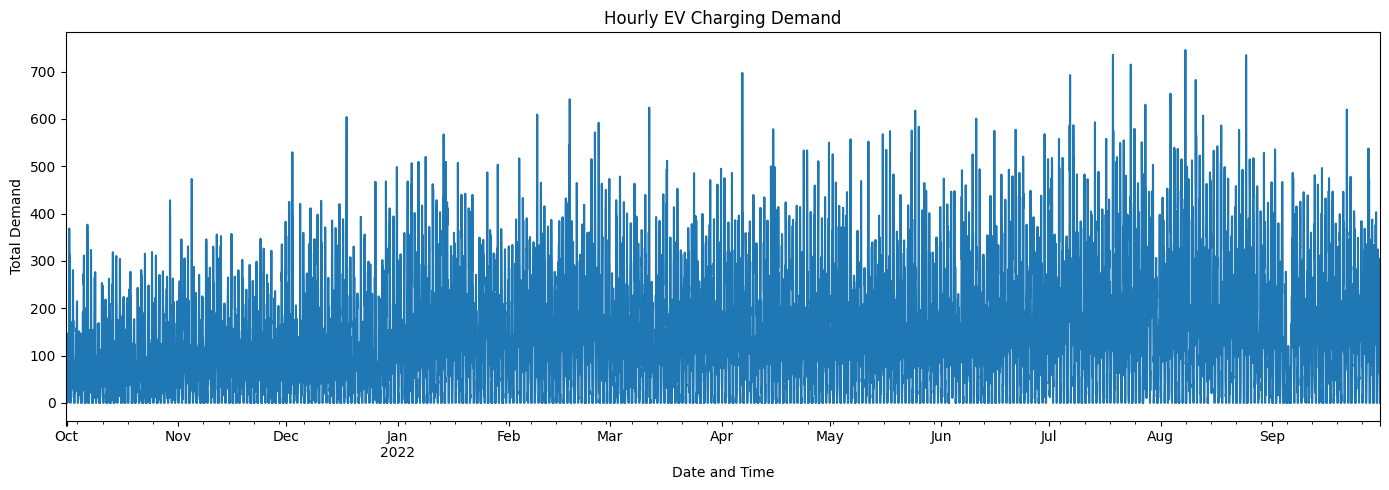

In [7]:
plt.figure(figsize=(14, 5))

hourly_demand.plot()

plt.title("Hourly EV Charging Demand")

plt.xlabel("Date and Time")

plt.ylabel("Total Demand")

plt.tight_layout()

plt.show()

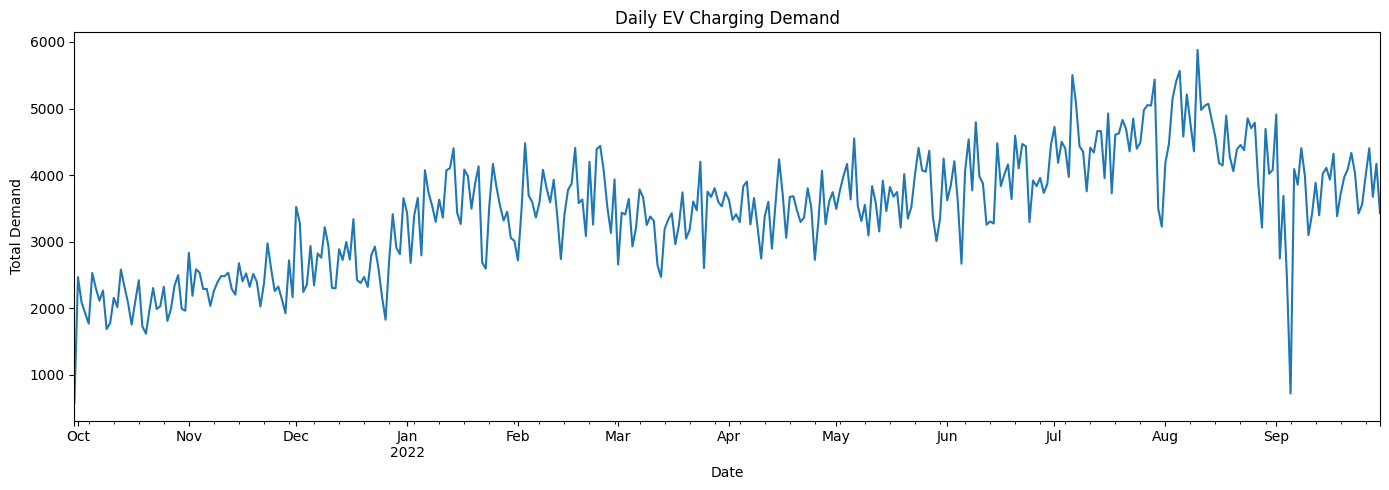

In [8]:
plt.figure(figsize=(14, 5))

daily_demand.plot()

plt.title("Daily EV Charging Demand")

plt.xlabel("Date")

plt.ylabel("Total Demand")

plt.tight_layout()

plt.show()

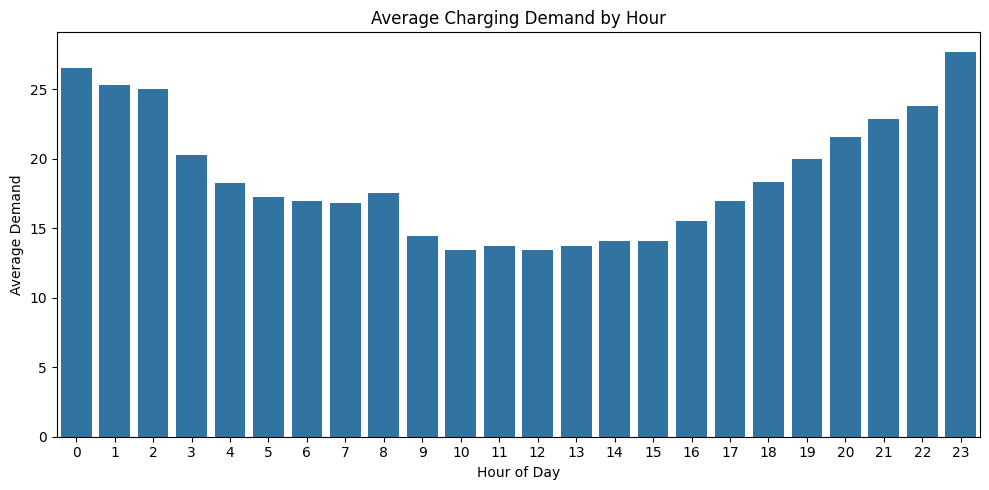

In [9]:
df["Hour"] = df["StartDatetime"].dt.hour

hourly_pattern = df.groupby("Hour")["Demand"].mean()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=hourly_pattern.index,
    y=hourly_pattern.values
)

plt.title("Average Charging Demand by Hour")

plt.xlabel("Hour of Day")

plt.ylabel("Average Demand")

plt.tight_layout()

plt.show()

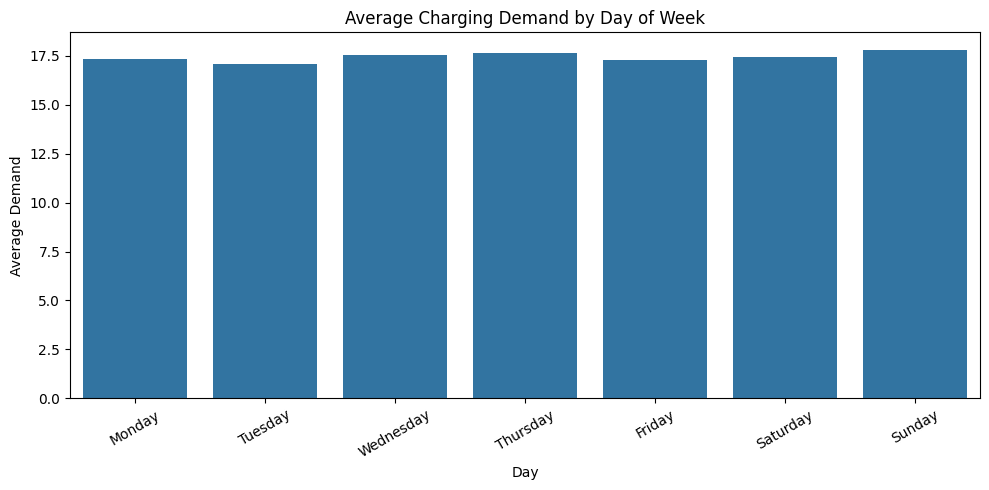

In [10]:
df["DayOfWeek"] = df["StartDatetime"].dt.dayofweek

weekday_pattern = df.groupby("DayOfWeek")["Demand"].mean()

days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_pattern.index,
    y=weekday_pattern.values
)

plt.xticks(
    ticks=range(7),
    labels=days,
    rotation=30
)

plt.title("Average Charging Demand by Day of Week")

plt.xlabel("Day")

plt.ylabel("Average Demand")

plt.tight_layout()

plt.show()

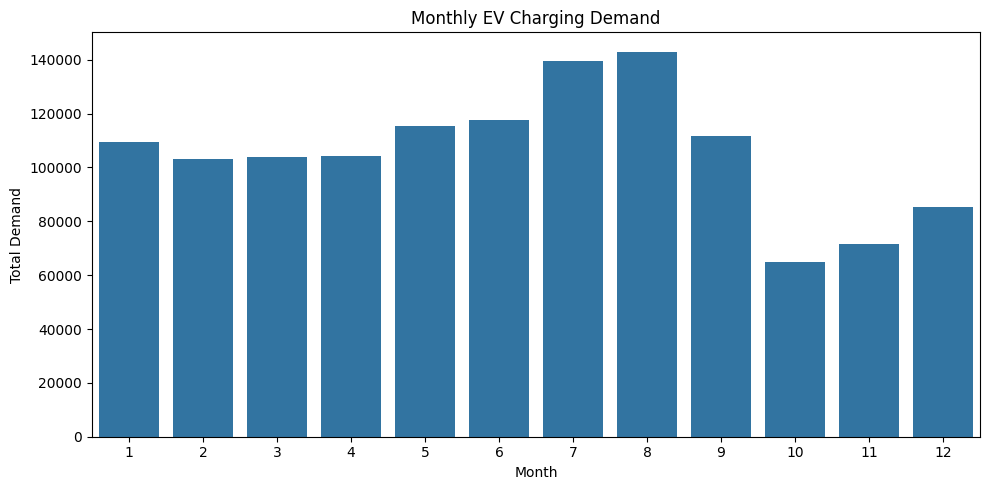

In [11]:
df["Month"] = df["StartDatetime"].dt.month

monthly_demand = df.groupby("Month")["Demand"].sum()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_demand.index,
    y=monthly_demand.values
)

plt.title("Monthly EV Charging Demand")

plt.xlabel("Month")

plt.ylabel("Total Demand")

plt.tight_layout()

plt.show()

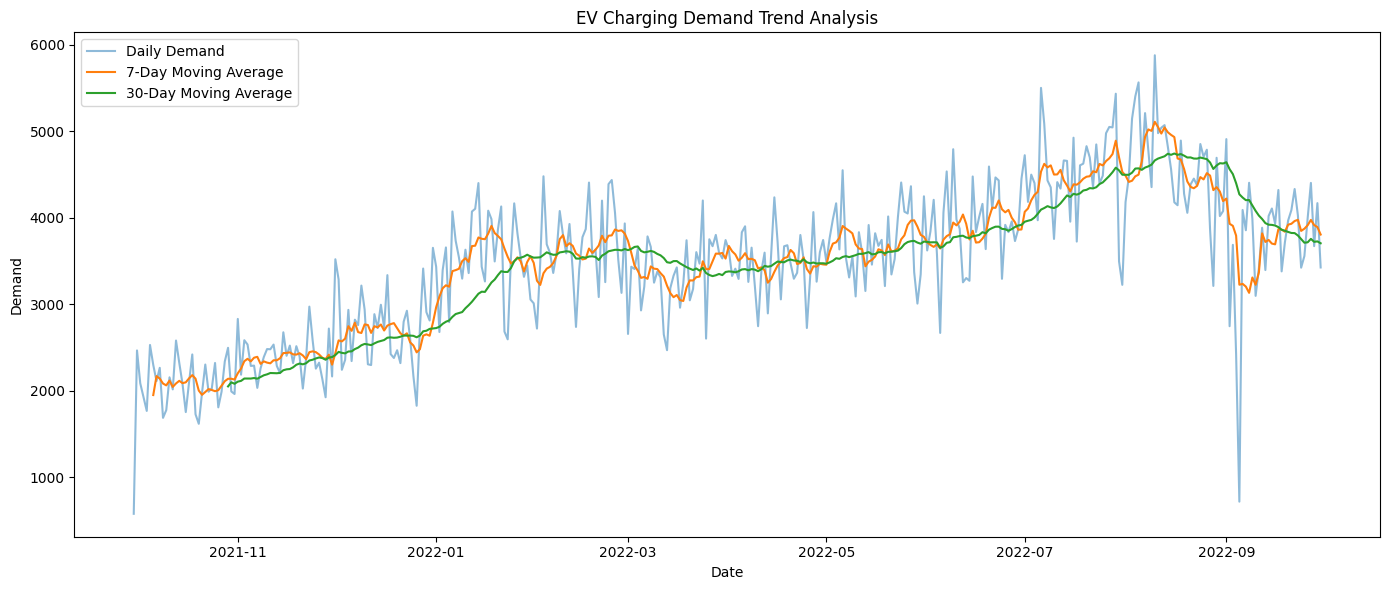

In [12]:
trend_data = daily_demand.to_frame(name="Demand")

trend_data["7_Day_Moving_Average"] = (
    trend_data["Demand"].rolling(window=7).mean()
)

trend_data["30_Day_Moving_Average"] = (
    trend_data["Demand"].rolling(window=30).mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    trend_data.index,
    trend_data["Demand"],
    label="Daily Demand",
    alpha=0.5
)

plt.plot(
    trend_data.index,
    trend_data["7_Day_Moving_Average"],
    label="7-Day Moving Average"
)

plt.plot(
    trend_data.index,
    trend_data["30_Day_Moving_Average"],
    label="30-Day Moving Average"
)

plt.title("EV Charging Demand Trend Analysis")

plt.xlabel("Date")

plt.ylabel("Demand")

plt.legend()

plt.tight_layout()

plt.show()

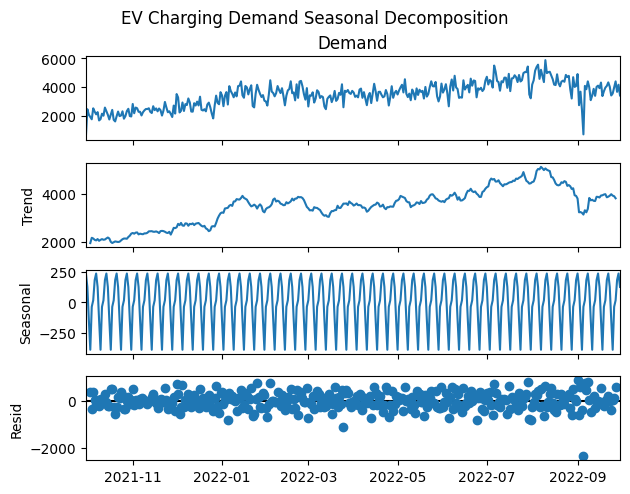

In [13]:
if len(daily_demand) >= 14:

    decomposition = seasonal_decompose(
        daily_demand,
        model="additive",
        period=7
    )

    decomposition.plot()

    plt.suptitle(
        "EV Charging Demand Seasonal Decomposition",
        y=1.02
    )

    plt.show()

else:

    print("Insufficient data for seasonal decomposition.")

In [14]:
series = daily_demand.copy()

series = series.asfreq("D").fillna(0)

split_index = int(len(series) * 0.80)

train = series.iloc[:split_index]

test = series.iloc[split_index:]

print("Training Records:", len(train))

print("Testing Records:", len(test))

print("Training Period:", train.index.min(), "to", train.index.max())

print("Testing Period:", test.index.min(), "to", test.index.max())

Training Records: 292
Testing Records: 74
Training Period: 2021-09-30 00:00:00 to 2022-07-18 00:00:00
Testing Period: 2022-07-19 00:00:00 to 2022-09-30 00:00:00


In [15]:
window = 7

moving_average_predictions = []

history = list(train.values)

for actual_value in test.values:

    prediction = np.mean(history[-window:])

    moving_average_predictions.append(prediction)

    history.append(actual_value)

moving_average_predictions = np.array(
    moving_average_predictions
)

print("Moving Average Forecasting Completed")

Moving Average Forecasting Completed


In [16]:
if len(train) >= 14:

    if len(train) >= 28:

        es_model = ExponentialSmoothing(
            train,
            trend="add",
            seasonal="add",
            seasonal_periods=7,
            initialization_method="estimated"
        )

    else:

        es_model = ExponentialSmoothing(
            train,
            trend="add",
            seasonal=None,
            initialization_method="estimated"
        )

    es_fitted = es_model.fit(optimized=True)

    es_predictions = es_fitted.forecast(
        len(test)
    )

    print("Exponential Smoothing Completed")

else:

    raise ValueError(
        "Insufficient training data for Exponential Smoothing."
    )

Exponential Smoothing Completed


In [17]:
forecast_results = []

# Moving Average
mae_ma = mean_absolute_error(
    test,
    moving_average_predictions
)

rmse_ma = np.sqrt(
    mean_squared_error(
        test,
        moving_average_predictions
    )
)

forecast_results.append({

    "Model": "Moving Average",

    "MAE": mae_ma,

    "RMSE": rmse_ma

})

# Exponential Smoothing
mae_es = mean_absolute_error(
    test,
    es_predictions
)

rmse_es = np.sqrt(
    mean_squared_error(
        test,
        es_predictions
    )
)

forecast_results.append({

    "Model": "Exponential Smoothing",

    "MAE": mae_es,

    "RMSE": rmse_es

})

forecast_results_df = pd.DataFrame(
    forecast_results
).sort_values(
    by="RMSE",
    ascending=True
)

forecast_results_df

,Model,MAE,RMSE
0,Moving Average,495.038494,686.474209
1,Exponential Smoothing,791.533621,1029.401703


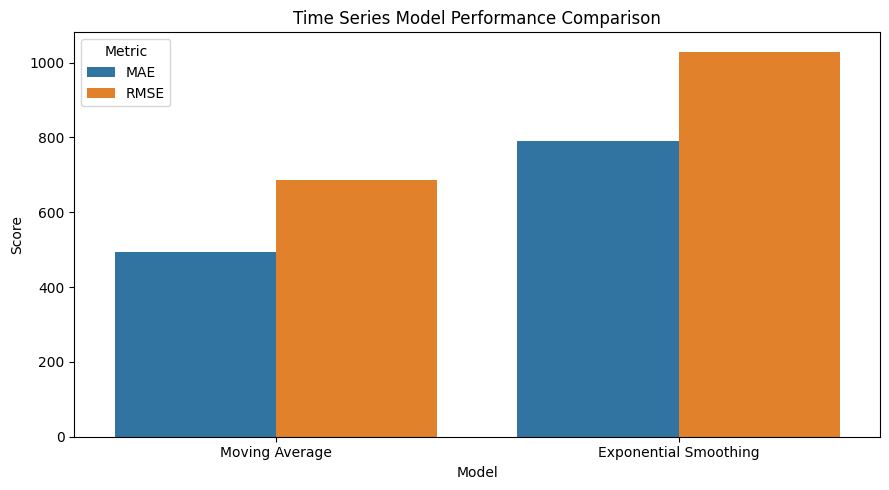

In [18]:
plt.figure(figsize=(9, 5))

forecast_melted = forecast_results_df.melt(
    id_vars="Model",
    value_vars=["MAE", "RMSE"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=forecast_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Time Series Model Performance Comparison")

plt.tight_layout()

plt.show()

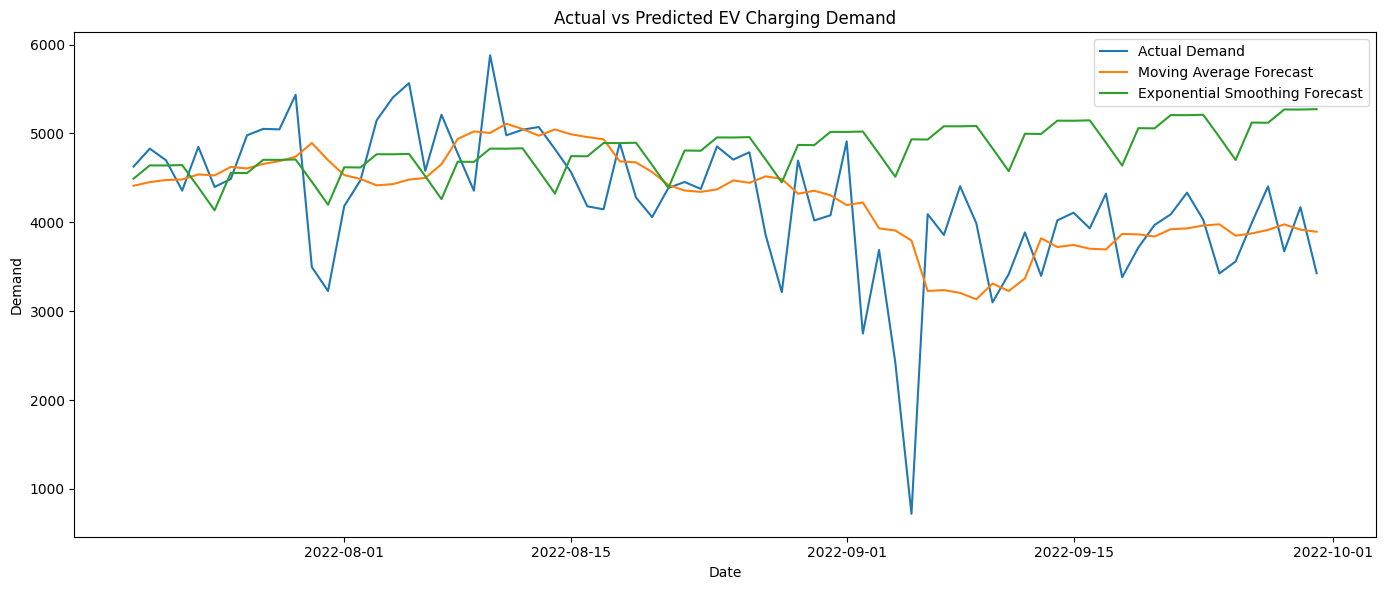

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test.values,
    label="Actual Demand"
)

plt.plot(
    test.index,
    moving_average_predictions,
    label="Moving Average Forecast"
)

plt.plot(
    test.index,
    es_predictions,
    label="Exponential Smoothing Forecast"
)

plt.title("Actual vs Predicted EV Charging Demand")

plt.xlabel("Date")

plt.ylabel("Demand")

plt.legend()

plt.tight_layout()

plt.show()

In [20]:
best_forecast_name = forecast_results_df.iloc[0]["Model"]

print("Best Forecasting Model:", best_forecast_name)

print("\nBest Model Performance:")

print(forecast_results_df.iloc[0])

Best Forecasting Model: Moving Average

Best Model Performance:
Model    Moving Average
MAE          495.038494
RMSE         686.474209
Name: 0, dtype: object


In [21]:
forecast_period = 30

if best_forecast_name == "Moving Average":

    history = list(series.values)

    future_predictions = []

    for _ in range(forecast_period):

        prediction = np.mean(history[-window:])

        future_predictions.append(prediction)

        history.append(prediction)

else:

    future_predictions = es_fitted.forecast(
        forecast_period
    ).values


future_dates = pd.date_range(
    start=series.index[-1] + pd.Timedelta(days=1),
    periods=forecast_period,
    freq="D"
)

future_forecast = pd.DataFrame({

    "Date": future_dates,

    "Predicted Demand": future_predictions

})

future_forecast.head(10)

,Date,Predicted Demand
0,2022-10-01,3807.655714
1,2022-10-02,3862.386531
2,2022-10-03,3905.738892
3,2022-10-04,3892.950162
4,2022-10-05,3819.917328
5,2022-10-06,3840.842661
6,2022-10-07,3793.750184
7,2022-10-08,3846.177353
8,2022-10-09,3851.680445
9,2022-10-10,3850.151004


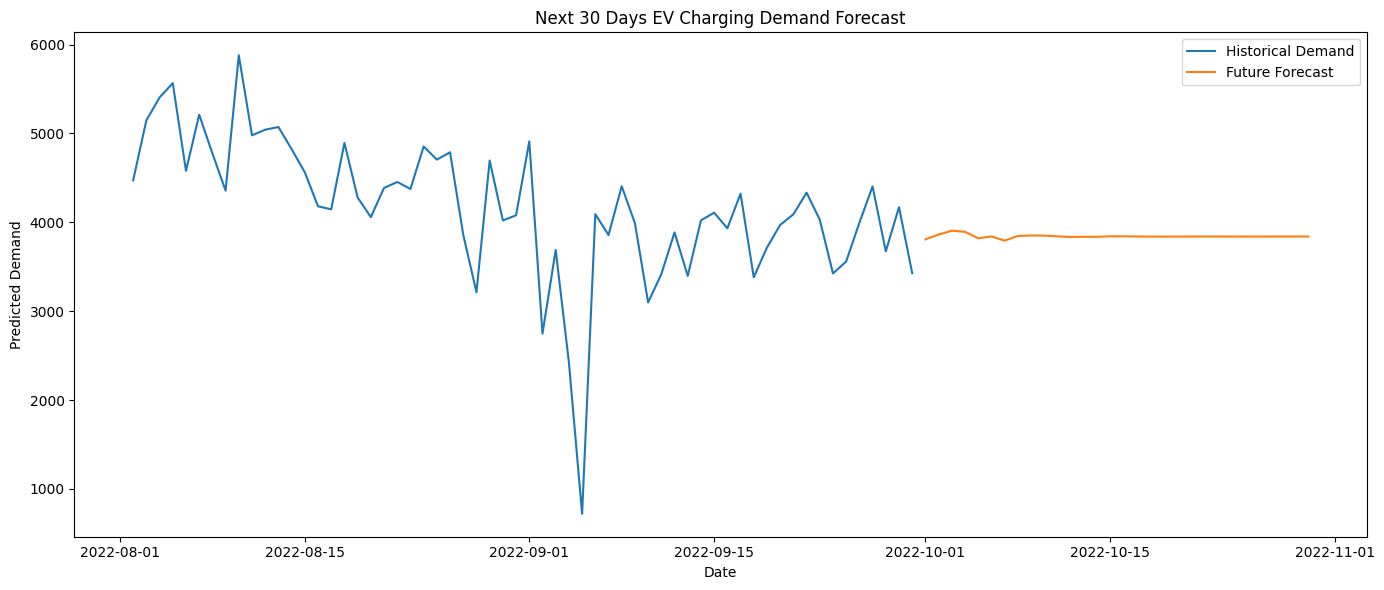

In [22]:
plt.figure(figsize=(14, 6))

plt.plot(
    series.index[-60:],
    series.values[-60:],
    label="Historical Demand"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["Predicted Demand"],
    label="Future Forecast"
)

plt.title("Next 30 Days EV Charging Demand Forecast")

plt.xlabel("Date")

plt.ylabel("Predicted Demand")

plt.legend()

plt.tight_layout()

plt.show()

In [23]:
forecast_results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "time_series_model_comparison.csv"
    ),
    index=False
)

future_forecast.to_csv(
    os.path.join(
        RESULT_DIR,
        "future_demand_forecast.csv"
    ),
    index=False
)

print("Forecasting Results Saved Successfully!")

Forecasting Results Saved Successfully!


In [24]:
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_forecast_model.pkl"
)

if best_forecast_name == "Exponential Smoothing":

    joblib.dump(
        es_fitted,
        MODEL_PATH
    )

else:

    moving_average_model = {
        "model": "Moving Average",
        "window": window,
        "history": list(series.values)
    }

    joblib.dump(
        moving_average_model,
        MODEL_PATH
    )

print("Best Forecasting Model Saved Successfully!")

print("Model:", best_forecast_name)

print("Location:", MODEL_PATH)

Best Forecasting Model Saved Successfully!
Model: Moving Average
Location: c:\Users\yendl\OneDrive\Documents\GUVI Folder\ev-charging_project\models\best_forecast_model.pkl
